# Physical Layer: Nodes, Devices & Links
*Fabian Nütz*

The physical layer represents the **hardware topology** of your ICT network. In this notebook you will:

- Create nodes with link-type support and optional geodata
- Create devices of different types
- Wire them together with directed links (including multicast)
- Understand the `from_elt` / `to_elt` direction convention
- Visualize the resulting physical graph

For this and coming notebooks, we'll be working with a very basic example network. Its physical layer looks like this:

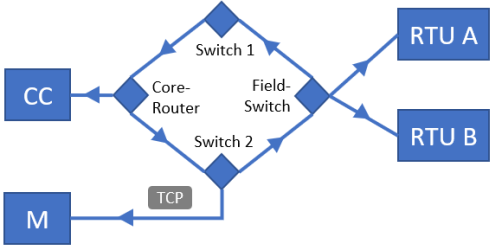

The boxes are devices: a Control Center (CC), a Monitoring (M), and two Remote Terminal Units (RTU A and RTU B).  The diamond-shaped elements are nodes. All connecting links use LAN/Ethernet by default. The little arrows on links point into the "downstream" direction. 

Next, we'll create this network in pandaict.

## Setup

In [1]:
import pandaict as pi
from pandaict.utils.enums import NodeType, DeviceType
from pandaict.plot import create_plot
import matplotlib.pyplot as plt

## Creating an empty network

In [2]:
net = pi.create_empty_network(name='Physical Layer Demo')
print(net.name)

Physical Layer Demo


## Nodes

A **node** is a network interconnection point. Nodes can connect links of one or more `link_types`. If a node supports multiple link types, it is assumed to perform physical-layer translation between them but *not* protocol translation, which would require a converter device/app (see notebook 03).

Key parameters:
- `name` — human-readable label
- `node_type` — `NodeType.SWITCH` or `NodeType.ROUTER`
- `link_types` — list of supported link type names (strings)
- `geodata` — optional geographic coordinates
- `in_service` — whether the node is operational (default `True`)

In [3]:
# A simple router with two link types
n_core = pi.create_ict_node(net, name='Core-Router',
                            node_type=NodeType.ROUTER,
                            link_types=['Fiber', 'LAN1000'])

# Switches with one link type
n_sw1 = pi.create_ict_node(net, name='Switch-1',
                           node_type=NodeType.SWITCH,
                           link_types=['LAN1000'])

n_sw2 = pi.create_ict_node(net, name='Switch-2',
                           node_type=NodeType.SWITCH,
                           link_types=['LAN1000'])

# A switch-type node with geodata (GeoJSON-like dict)
n_field = pi.create_ict_node(net, name='Field-Switch',
                             node_type=NodeType.SWITCH,
                             link_types=['LAN1000'],
                             geodata={'type': 'Point',
                                      'coordinates': (52.52, 13.40)})

print('Nodes:', len(net.node))
display(net.node[['name', 'type', 'link_types', 'geodata']])

Nodes: 4


,name,type,link_types,geodata
0,Core-Router,NodeType.ROUTER,"[Fiber, LAN1000]",None
1,Switch-1,NodeType.SWITCH,[LAN1000],None
2,Switch-2,NodeType.SWITCH,[LAN1000],None
3,Field-Switch,NodeType.SWITCH,[LAN1000],"{'type': 'Point', 'coordinates': (52.52, 13.4)}"


## Devices

A **device** is a physical communication endpoint. Every app (logical layer) runs on exactly one device.

Built-in device types:
- `DeviceType.SERVER` — general-purpose compute node
- `DeviceType.RTU` — Remote Terminal Unit (field device)
- `DeviceType.CONVERTER` — hosts protocol-converter apps (see notebook 03)

Key parameters:
- `name`, `device_type`, `in_service`

In [4]:
ctrl_server = pi.create_ict_device(net, name='CTRL-Server',
                                   device_type=DeviceType.SERVER)
rtu_a = pi.create_ict_device(net, name='RTU-A',
                             device_type=DeviceType.RTU)
rtu_b = pi.create_ict_device(net, name='RTU-B',
                             device_type=DeviceType.RTU)

print('Devices:', len(net.device))
display(net.device[['name', 'type']])

Devices: 3


,name,type
0,CTRL-Server,DeviceType.SERVER
1,RTU-A,DeviceType.RTU
2,RTU-B,DeviceType.RTU


## Device-App pairs with `create_ict_devapp()`

Devices may host an arbitrary number of apps, but often only a single app is hosted. The convenience function `create_ict_devapp()` creates both device and app at once and returns `(device_tuple, app_tuple)`:

In [5]:
from pandaict.utils.enums import AppType

(m_dev, m_app) = pi.create_ict_devapp(net, name='Monitoring',
                                      device_type=DeviceType.SERVER,
                                      app_type=AppType.WEBSERVER)
print('Device:', m_dev, '| App:', m_app)
print('Device name:', net.device.loc[m_dev[1]]['name'])
print('App name:   ', net.app.loc[m_app[1]]['name'])

Device: ('device', 3) | App: ('app', 0)
Device name: Monitoring
App name:    Monitoring


## Links

Links are directed physical connections. The direction convention is:

> **`from_elt` -> `to_elt`   = downstream** <br>
> **`to_elt`   -> `from_elt` = upstream**

A link can have multiple `to_elt` entries to model **multicast** (e.g., one switch port feeding many end devices).

Key parameters:
- `from_elt` — single element tuple (node or device)
- `to_elt` — **list** of element tuples
- `link_type` — string matching a key in `net.std_types['link']`
- `length_km` — physical cable length (used for bit error rate)
- `in_service` — whether the link is operational (default True)
- `mtbf_h`, `mttr_h`, `ber` — reliability metrics

In [6]:
# Wire the network: a redundant ring with a spur

# Core ring: Switch-1 <-> Core-Router <-> Switch-2 <-> Field-Switch <-> Switch-1
pi.create_ict_link(net, name='L-SW1-Core',  from_elt=n_sw1,   to_elt=[n_core],  link_type='LAN1000')
pi.create_ict_link(net, name='L-Core-SW2',  from_elt=n_core,  to_elt=[n_sw2],   link_type='LAN1000')
pi.create_ict_link(net, name='L-SW2-Field', from_elt=n_sw2,   to_elt=[n_field], link_type='LAN1000')
pi.create_ict_link(net, name='L-Field-SW1', from_elt=n_field, to_elt=[n_sw1],   link_type='LAN1000')

# Spur: Core-Router -> CTRL-Server (downstream)
pi.create_ict_link(net, name='L-Core-CTRL',  from_elt=n_core,       to_elt=[ctrl_server], link_type='LAN1000')

# Field devices connected to Field-Switch
pi.create_ict_link(net, name='L-Field-RTU-A', from_elt=n_field, to_elt=[rtu_a], link_type='LAN1000', length_km=0.5)
pi.create_ict_link(net, name='L-Field-RTU-B', from_elt=n_field, to_elt=[rtu_b], link_type='LAN1000', length_km=1.2)

# Monitoring device on Switch-2
pi.create_ict_link(net, name='L-SW2-Mon', from_elt=n_sw2, to_elt=[m_dev], link_type='LAN1000')

print('Links:', len(net.link))
display(net.link[['name', 'type', 'from', 'to', 'length_km']])

Links: 8


,name,type,from,to,length_km
0,L-SW1-Core,LAN1000,"(node, 1)","[(node, 0)]",0.0
1,L-Core-SW2,LAN1000,"(node, 0)","[(node, 2)]",0.0
2,L-SW2-Field,LAN1000,"(node, 2)","[(node, 3)]",0.0
3,L-Field-SW1,LAN1000,"(node, 3)","[(node, 1)]",0.0
4,L-Core-CTRL,LAN1000,"(node, 0)","[(device, 0)]",0.0
5,L-Field-RTU-A,LAN1000,"(node, 3)","[(device, 1)]",0.5
6,L-Field-RTU-B,LAN1000,"(node, 3)","[(device, 2)]",1.2
7,L-SW2-Mon,LAN1000,"(node, 2)","[(device, 3)]",0.0


**Important link rules recap**:
- `from_elt` is always a single element, `to_elt` is a **list**.
- Direct device-to-device links are not allowed — always route through a node.
- The `from → to` direction defines downstream flow for asymmetric link technologies.

## Summary

You now have a complete physical network:
- 4 nodes (1 router, 3 switches), one with geodata
- 4 devices (server, 2 RTUs, monitoring)
- 9 links forming a redundant ring topology with spurs

In the next notebook we add the **logical layer** — apps and connections — on top of this physical foundation.

Next: [03 – Logical Layer](03_logical_layer.ipynb)